# setup (load data)

In [ ]:
import os, scipy.io as sio, pandas as pd
import numpy as np 
import pymc as pm, arviz as az, nutpie
import matplotlib.pyplot as plt
import scipy.stats as st
import pytensor.tensor as pt

root_folder = '/home/habv0/Q5078local'
output_folder = './model-outputs'

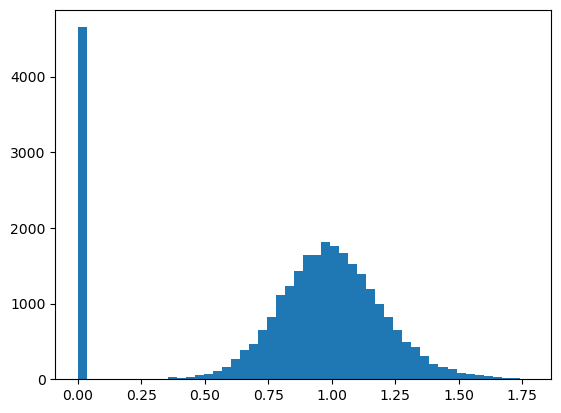

In [2]:
def load_data(file):
    assert os.path.isfile(file)
    mat = sio.loadmat(file)

    df = pd.DataFrame()
    for field in mat['df'].dtype.names:
        df[field] = mat['df'][field][0,0].flatten()
        
    return df

# load data
filename = os.path.join(root_folder,'contrDetectBadpt/derivatives/eeg/ic/compiled-data-struct.mat')
df = load_data(filename)
df['y'] = df['accuracy']

dat = df.copy()
dat = dat.loc[dat['blinks']==0,:]

# code unique sessions
dat['p'] = dat.groupby(['sub','ses']).ngroup()

# subtract phase from ERP best predicted
dat['phi'] = dat['phi_echt']
dat['phi'] = np.arctan2(np.sin(dat['phi']-dat['phase_offset']), np.cos(dat['phi']-dat['phase_offset']))
dat.loc[np.isnan(dat['phi']),'phi'] = 0  # this will be nullified by the 0 amplitude here anyway

dat['pow'] = np.log1p(dat['amp_echt'])
dat.loc[np.isnan(dat['pow']),'pow'] = 0
dat['pow'] = dat.groupby('p')['pow'].transform(lambda x: x/x[x>0].mean())  # fix scale of non-zero
plt.hist(dat['pow'],50);

# fit behavioural model

In [4]:
coords = dict()
coords['p'] = np.unique(dat['p'])
coords['param'] = ['n','c50','b0']

with pm.Model(coords=coords) as model:
    c = pm.Data('c', dat['contrast'])
    y = pm.Data('y', dat['y'])
    p = pm.Data('p', dat['p'])

    # hierarchical parameters
    mu_n = pm.HalfNormal('mu_n', 3)  # slope
    mu_c50 = pm.Beta('mu_c50', 2, 2)
    mu_b0 = pm.Normal('mu_b0', 2, 1)

    sigma = pm.HalfNormal('sigma', .5, dims='param')
    Z = pm.Normal('Z', dims=['param','p'])

    # participant parameters
    Rmax = 5
    n = pm.Deterministic('n', mu_n*np.exp(Z[0]*sigma[0]), dims='p')
    c50 = pm.Deterministic('c50', pm.math.invlogit(pm.math.logit(mu_c50)+Z[1]*sigma[1]), dims='p')
    b0 = pm.Deterministic('b0', mu_b0+Z[2]*sigma[2], dims='p')

    # transducer functio
    T = c**n[p] / (c**n[p] + c50[p]**n[p])

    psi = 1-pm.math.invprobit(b0[p] - Rmax*T)
    yobs = pm.Bernoulli('y_obs', p=psi, observed=y)

In [ ]:
compiled = nutpie.compile_pymc_model(model, backend='jax', gradient_backend='jax')
trace = nutpie.sample(compiled, chains=4)
with model:
    pm.compute_log_likelihood(trace)

Progress,Draws,Divergences,Step Size,Gradients/Draw
,906,0,0.20,63
,900,0,0.21,63
,938,0,0.20,31
,955,0,0.21,31


/home/habv0/miniforge3/envs/sbi-inf/lib/python3.13/site-packages/rich/live.py:256: UserWarning: install 
"ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

'./model-outputs/model-1IFC-beh-fit.nc'

In [6]:
# save
az.to_netcdf(trace, os.path.join(output_folder,'inhib-model-1IFC-fit-beh.nc'))

'./model-outputs/inhib-model-1IFC-fit-beh.nc'

# fit baseline/response gain models

In [20]:
coords = dict()
coords['p'] = np.unique(dat['p'])
coords['param'] = ['n','c50','b0','b','g']

with pm.Model(coords=coords) as model:
    c = pm.Data('c', dat['contrast'])
    y = pm.Data('y', dat['y'])
    p = pm.Data('p', dat['p'])
    phase = pm.Data('phase', dat['phi'])
    power = pm.Data('power', dat['pow'])

    # hierarchical parameters
    mu_n = pm.HalfNormal('mu_n', 3)  # slope
    mu_c50 = pm.Beta('mu_c50', 2, 2)
    mu_b0 = pm.Normal('mu_b0', 2, 1)
    mu_b = pm.Normal('mu_b', 0, 2)  # inhibition of baseline
    mu_g = pm.Normal('mu_g', 0, 2)  # inhibition of response gain
    
    sigma = pm.HalfNormal('sigma', .5, dims='param')
    Z = pm.Normal('Z', dims=['param','p'])

    # participant parameters
    Rmax = 5
    n = pm.Deterministic('n', mu_n*np.exp(Z[0]*sigma[0]), dims='p')
    c50 = pm.Deterministic('c50', pm.math.invlogit(pm.math.logit(mu_c50)+Z[1]*sigma[1]), dims='p')
    b0 = pm.Deterministic('b0', mu_b0+Z[2]*sigma[2], dims='p')
    b = pm.Deterministic('b', mu_b+Z[3]*sigma[3], dims='p')
    g = pm.Deterministic('g', mu_g+Z[4]*sigma[4], dims='p')

    # transducer function
    T = c**n[p] / (c**n[p] + c50[p]**n[p])

    # phasic inhibition
    m = pm.Beta('m',1,1)
    I = power*(1+m*np.cos(phase)) 

    psi = 1-pm.math.invprobit((b0[p]+b[p]*I) - Rmax*np.exp(g[p]*I)*T)
    yobs = pm.Bernoulli('y_obs', p=psi, observed=y)

In [21]:
compiled = nutpie.compile_pymc_model(model, backend='jax', gradient_backend='jax')
trace = nutpie.sample(compiled, chains=4, seed=12345)
with model:
    pm.compute_log_likelihood(trace)

/home/habv0/miniforge3/envs/sbi-inf/lib/python3.13/site-packages/rich/live.py:256: UserWarning: install 
"ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

In [23]:
# save
az.to_netcdf(trace, os.path.join(output_folder,'inhib-model-1IFC-fit-bg.nc'))

'./model-outputs/inhib-model-1IFC-fit-bg.nc'

# fit contrast gain model

In [12]:
coords = dict()
coords['p'] = np.unique(dat['p'])
coords['param'] = ['n','c50','b0','Cg']

with pm.Model(coords=coords) as model:
    c = pm.Data('c', dat['contrast'])
    y = pm.Data('y', dat['y'])
    p = pm.Data('p', dat['p'])
    phase = pm.Data('phase', dat['phi'])
    power = pm.Data('power', dat['pow'])

    # hierarchical parameters
    mu_n = pm.HalfNormal('mu_n', 3)  # slope
    mu_c50 = pm.Beta('mu_c50', 2, 2)
    mu_b0 = pm.Normal('mu_b0', 2, 1)
    mu_Cg = pm.Normal('mu_Cg', 0, 2)  

    sigma = pm.HalfNormal('sigma', .5, dims='param')
    Z = pm.Normal('Z', dims=['param','p'])

    # participant parameters
    Rmax = 5
    n = pm.Deterministic('n', mu_n*np.exp(Z[0]*sigma[0]), dims='p')
    c50 = pm.Deterministic('c50', pm.math.invlogit(pm.math.logit(mu_c50)+Z[1]*sigma[1]), dims='p')
    b0 = pm.Deterministic('b0', mu_b0+Z[2]*sigma[2], dims='p')
    Cg = pm.Deterministic('Cg', mu_Cg+Z[3]*sigma[3], dims='p')

    # phasic inhibition
    m = pm.Beta('m',1,1)
    I = power*(1+m*np.cos(phase)) 

    # transducer function
    c50_ = pm.math.invlogit(pm.math.logit(c50[p]) - Cg[p]*I)
    T = c**n[p] / (c**n[p] + c50_**n[p])

    psi = 1-pm.math.invprobit(b0[p] - Rmax*T)
    yobs = pm.Bernoulli('y_obs', p=psi, observed=y)

In [13]:
compiled = nutpie.compile_pymc_model(model, backend='jax', gradient_backend='jax')
trace = nutpie.sample(compiled, chains=4, seed=12345)
with model:
    pm.compute_log_likelihood(trace)

/home/habv0/miniforge3/envs/sbi-inf/lib/python3.13/site-packages/rich/live.py:256: UserWarning: install 
"ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

In [14]:
# save
az.to_netcdf(trace, os.path.join(output_folder,'inhib-model-1IFC-fit-Cg.nc'))

'./model-outputs/inhib-model-1IFC-fit-Cg.nc'

# noise model

In [ ]:
coords = dict()
coords['p'] = np.unique(dat['p'])
coords['param'] = ['n','c50','b0','Nz']

with pm.Model(coords=coords) as model:
    c = pm.Data('c', dat['contrast'])
    y = pm.Data('y', dat['y'])
    p = pm.Data('p', dat['p'])
    phase = pm.Data('phase', dat['phi'])
    power = pm.Data('power', dat['pow'])

    # hierarchical parameters
    mu_n = pm.HalfNormal('mu_n', 3)  # slope
    mu_c50 = pm.Beta('mu_c50', 2, 2)
    mu_b0 = pm.Normal('mu_b0', 2, 1)
    mu_Nz = pm.Normal('mu_Nz', 0, 2)  
    sigma = pm.HalfNormal('sigma', .5, dims='param')
    Z = pm.Normal('Z', dims=['param','p'])

    # participant parameters
    Rmax = 5
    n = pm.Deterministic('n', mu_n*np.exp(Z[0]*sigma[0]), dims='p')
    c50 = pm.Deterministic('c50', pm.math.invlogit(pm.math.logit(mu_c50)+Z[1]*sigma[1]), dims='p')
    b0 = pm.Deterministic('b0', mu_b0+Z[2]*sigma[2], dims='p')
    Nz = pm.Deterministic('Nz', mu_Nz+Z[3]*sigma[3], dims='p')

    # phasic inhibition
    m = pm.Beta('m',1,1)
    I = power*(1+m*np.cos(phase)) 

    # transducer function
    T = c**n[p] / (c**n[p] + c50[p]**n[p])

    psi = 1-pm.math.invprobit((b0[p] - Rmax*T)/pm.math.exp(Nz[p]*I))
    yobs = pm.Bernoulli('y_obs', p=psi, observed=y)

In [17]:
compiled = nutpie.compile_pymc_model(model, backend='jax', gradient_backend='jax')
trace = nutpie.sample(compiled, chains=4, seed=12345)
with model:
    pm.compute_log_likelihood(trace)

/home/habv0/miniforge3/envs/sbi-inf/lib/python3.13/site-packages/rich/live.py:256: UserWarning: install 
"ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

In [19]:
# save
az.to_netcdf(trace, os.path.join(output_folder,'inhib-model-1IFC-fit-Nz.nc'))

'./model-outputs/inhib-model-1IFC-fit-Nz.nc'